In [41]:
import yfinance as yf
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:

nifty = yf.download("^NSEI", start="2010-01-01")
nifty.columns = nifty.columns.get_level_values(0)   # flatten column names
nifty.to_csv("nifty50_raw.csv")
print(nifty.shape)
print(nifty.head())

[*********************100%***********************]  1 of 1 completed

(4119, 5)
Price             Close         High          Low         Open  Volume
Date                                                                  
2010-01-04  5232.200195  5238.450195  5167.100098  5200.899902       0
2010-01-05  5277.899902  5288.350098  5242.399902  5277.149902       0
2010-01-06  5281.799805  5310.850098  5260.049805  5278.149902       0
2010-01-07  5263.100098  5302.549805  5244.750000  5281.799805       0
2010-01-08  5244.750000  5276.750000  5234.700195  5264.250000       0


In [31]:
df=pd.read_csv("C:/Users/Kaif/Downloads/nifty50_raw.xls")

In [35]:
df.columns = df.columns.str.strip()         
df["Date"] = pd.to_datetime(df["Date"])
df = df.drop_duplicates("Date").sort_values("Date").reset_index(drop=True)

print(df["Date"].min(), df["Date"].max(), len(df))

2010-01-04 00:00:00 2026-10-09 00:00:00 4119


In [37]:
df

,Date,Close,High,Low,Open,Volume
0,2010-01-04,5232.200195,5238.450195,5167.100098,5200.899902,0
1,2010-01-05,5277.899902,5288.350098,5242.399902,5277.149902,0
2,2010-01-06,5281.799805,5310.850098,5260.049805,5278.149902,0
3,2010-01-07,5263.100098,5302.549805,5244.750000,5281.799805,0
4,2010-01-08,5244.750000,5276.750000,5234.700195,5264.250000,0
...,...,...,...,...,...,...
4114,2026-10-05,22555.750000,22621.800781,22397.099609,22532.400391,436700
4115,2026-10-06,22776.099609,22776.099609,22561.599609,22603.250000,328800
4116,2026-10-07,22603.050781,22717.650391,22546.300781,22690.449219,359000
4117,2026-10-08,22231.800781,22599.050781,22179.900391,22599.050781,357500


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4119 entries, 0 to 4118
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    4119 non-null   datetime64[ns]
 1   Close   4119 non-null   float64       
 2   High    4119 non-null   float64       
 3   Low     4119 non-null   float64       
 4   Open    4119 non-null   float64       
 5   Volume  4119 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 193.2 KB


2014 return on result day: 1.12 %
2019 return on result day: -0.69 %
2024 return on result day: -5.93 %


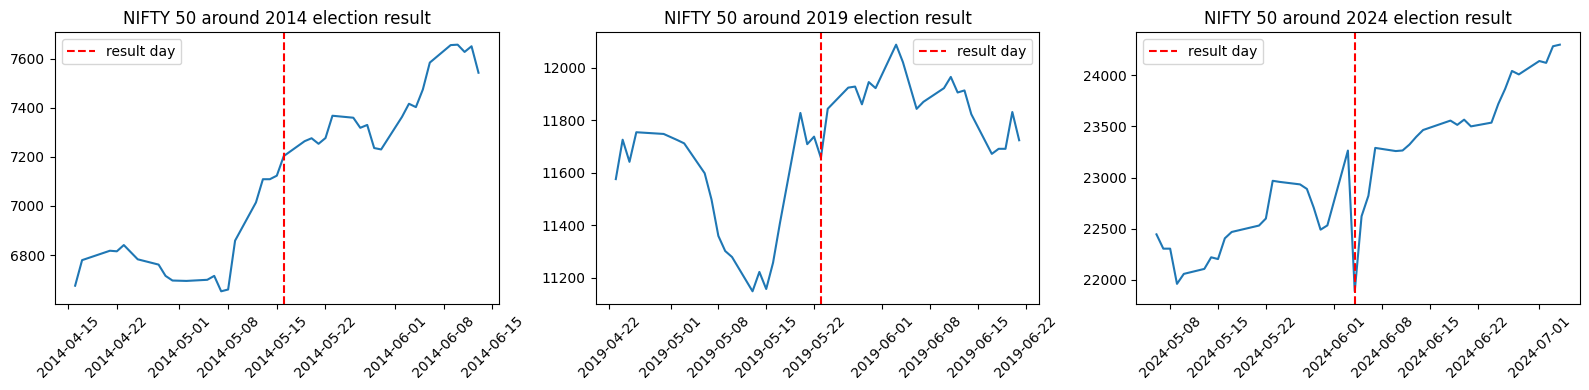

In [43]:
df = df.set_index("Date")
df["ret"] = df["Close"].pct_change() * 100

events = {"2014": "2014-05-16", "2019": "2019-05-23", "2024": "2024-06-04"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, d) in zip(axes, events.items()):
    d = pd.Timestamp(d)
    window = df.loc[d - pd.Timedelta(days=30): d + pd.Timedelta(days=30)]
    ax.plot(window.index, window["Close"])
    ax.axvline(d, color="red", linestyle="--", label="result day")
    ax.set_title(f"NIFTY 50 around {name} election result")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
    print(name, "return on result day:", round(df.loc[d, "ret"], 2), "%")

plt.tight_layout()
plt.show()